# 04 · Drive analysis

What drives produce, and how fast the defence collapses.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import config as C
pd.set_option("display.width", 160, "display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True,
                     "grid.alpha": .25, "figure.dpi": 110})
E = C.PROCESSED_DIR / "events"; D = C.DERIVED_DIR
rd  = lambda n: pd.read_parquet(D / f"{n}.parquet")
rev = lambda n: pd.read_parquet(E / f"{n}.parquet")
print("project:", C.PROJECT_ROOT.name)

project: basketball-intelligence


In [2]:
dr = rd("drives_features")
print(f"{len(dr)} drives | {dr.points_total.mean():.3f} pts/drive | "
      f"{dr.successful.mean():.1%} successful | {dr.blowby.mean():.1%} blowby")
dr.groupby("end_type").agg(n=("id","size"), ppd=("points_total","mean"),
  foul=("drew_foul","mean"), to=("turned_over","mean"), gain=("drive_gain_ft","mean"),
  help_closed=("help_closed_ft","mean"), paint_added=("paint_defenders_added","mean")).round(3)

660 drives | 0.559 pts/drive | 38.0% successful | 22.6% blowby


,n,ppd,foul,to,gain,help_closed,paint_added
end_type,,,,,,,
interiorPass,64,0.469,0.000,0.000,18.573999,7.036,1.391
kickout,184,0.418,0.016,0.071,15.849000,7.022,1.656
pullout,13,0.000,0.000,0.077,18.657000,5.319,2.000
pullup,96,0.781,0.073,0.000,13.719000,6.014,1.625
shotNearBasket,246,0.760,0.199,0.000,23.007999,8.420,2.041
stoppage,29,0.000,0.862,0.000,17.919001,6.151,1.690
turnover,28,0.000,0.143,1.000,17.002001,7.568,1.607


In [3]:
dr.groupby("category").agg(n=("id","size"), ppd=("points_total","mean"),
  blowby=("blowby","mean"), paint=("reached_paint","mean"),
  kickout=("passed_out","mean")).sort_values("n", ascending=False).round(3)

,n,ppd,blowby,paint,kickout
category,,,,,
pick,332,0.539,0.265,0.699,0.410
closeout,111,0.586,0.126,0.703,0.360
miscellaneous,76,0.632,0.237,0.750,0.395
iso,75,0.587,0.147,0.867,0.200
handoff,47,0.447,0.277,0.723,0.404
offBallScreen,19,0.632,0.263,0.737,0.421


## The defensive collapse curve

Second-nearest defender distance, sampled every 0.2 s from drive start, split by how the drive ended.

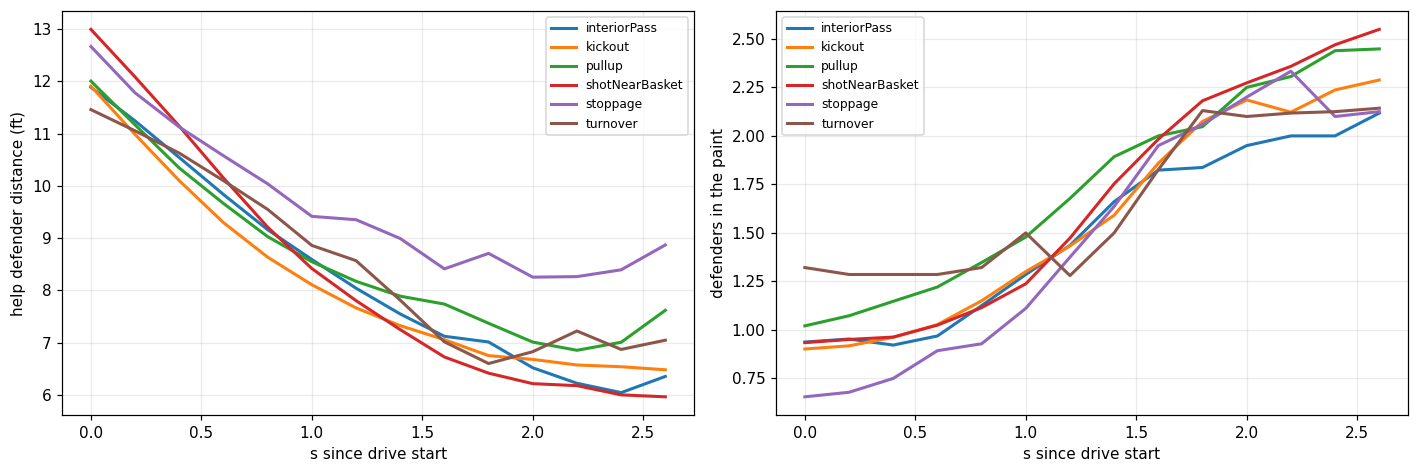

In [4]:
col = rd("drive_collapse").merge(dr[["id","end_type","successful"]],
                                 left_on="drive_id", right_on="id")
cc = col[col.t_since_start <= 2.6]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for k, g_ in cc.groupby("end_type"):
    if g_.drive_id.nunique() < 15: continue
    ax[0].plot(*g_.groupby("t_since_start").second_def_dist.mean().reset_index().values.T, lw=2, label=k)
    ax[1].plot(*g_.groupby("t_since_start").n_def_in_paint.mean().reset_index().values.T, lw=2, label=k)
ax[0].set_xlabel("s since drive start"); ax[0].set_ylabel("help defender distance (ft)"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("s since drive start"); ax[1].set_ylabel("defenders in the paint"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [5]:
from scipy import stats
d = dr.dropna(subset=["help_at_start","help_min"])
t, p = stats.ttest_rel(d.help_at_start, d.help_min)
print(f"help closes {d.help_closed_ft.mean():.2f} ft "
      f"({d.help_at_start.mean():.2f} -> {d.help_min.mean():.2f}), paired t={t:.1f}, p={p:.2g}")
print(f"paint defenders added: {dr.paint_defenders_added.mean():.2f}")
dr.groupby("successful").agg(n=("id","size"), gain=("drive_gain_ft","mean"),
  blowby=("blowby","mean"), help_closed=("help_closed_ft","mean"),
  paint_added=("paint_defenders_added","mean"), hull_min=("hull_min","mean")).round(3)

help closes 7.35 ft (12.30 -> 4.95), paired t=42.5, p=2.1e-190
paint defenders added: 1.77


,n,gain,blowby,help_closed,paint_added,hull_min
successful,,,,,,
False,409,17.847000,0.222,7.151,1.760,405.302
True,251,19.992001,0.231,7.667,1.799,415.987
